# Efficient LLM Fine-Tuning Using QLoRA

**Elevvo Pathways NLP Internship ? Task 9**

Fine-tune an instruction model for dialogue summarization on SAMSum using 4-bit QLoRA, then compare base and adapted generations. Scores are created only when the notebook is run. Use a Colab T4 GPU. The initial subset is for a first experiment, not a definitive benchmark.


## 1. Project Introduction

Keep the quantized base weights frozen while learning small low-rank adapter matrices. SAMSum provides real dialogues and human-written reference summaries. Later, both model versions will be evaluated on the same held-out examples.


## 2. Objectives

1. Inspect actual SAMSum splits, fields, examples, missing values, and duplicates.
2. Mask prompt tokens so supervised loss trains summary generation.
3. Fine-tune with resource-efficient QLoRA on one T4.
4. Compare the base and tuned model with identical inputs and decoding settings.
5. Save measured metrics, plots, predictions, and adapters reproducibly.


## 3. Environment Setup

Install a tested, mutually compatible Hugging Face stack. Colab supplies the CUDA-enabled PyTorch build, so this notebook deliberately does not reinstall PyTorch. After the install cell completes, restart the runtime once, then run the notebook from the top. The versions below match the recorded Tesla T4 run.


In [1]:
# Colab provides the CUDA-enabled PyTorch build; do not replace it here.
%pip install -q \
    "transformers==4.57.1" \
    "huggingface_hub==0.36.2" \
    "datasets==5.0.1" \
    "peft==0.21.2" \
    "bitsandbytes==0.50.2" \
    "accelerate==1.15.0" \
    "evaluate==0.4.3" \
    "rouge-score==0.1.2"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 4. GPU Verification

Check CUDA before loading weights. The T4 uses FP16 compute. Later cells check 4-bit bitsandbytes support and give an actionable error if unavailable.


In [2]:
import os, random, json, platform, sys
import numpy as np
import pandas as pd
import torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU not detected. Select Runtime > Change runtime type > T4 GPU and rerun.")
torch.cuda.manual_seed_all(SEED)
print("GPU:", torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GiB")
print("PyTorch:", torch.__version__, "CUDA:", torch.version.cuda, "Python:", platform.python_version())


GPU: Tesla T4
VRAM: 14.56 GiB
PyTorch: 2.11.0+cu130 CUDA: 13.0 Python: 3.13.16


In [3]:
import torch
import transformers
import huggingface_hub
import datasets
import peft
import bitsandbytes

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("Bitsandbytes:", bitsandbytes.__version__)

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not detected")

PyTorch: 2.11.0+cu130
Transformers: 4.57.1
Hugging Face Hub: 0.36.2
Datasets: 5.0.1
PEFT: 0.21.2
Bitsandbytes: 0.50.2
CUDA available: True
GPU: Tesla T4


## 5. Dataset Loading

Load the public Samsung SAMSum dataset through Hugging Face Datasets. Inspect actual splits, columns, and feature types. Loading errors include likely connection or Hub causes. Test rows remain reserved for final evaluation.


In [4]:
from datasets import load_dataset
DATASET_ID = "knkarthick/samsum"
try:
    raw = load_dataset(DATASET_ID)
except Exception as exc:
    raise RuntimeError(f"Could not load {DATASET_ID!r}. Check internet, dataset ID, and datasets installation/version; retry if the Hub is temporarily unavailable. Original error: {type(exc).__name__}: {exc}") from exc
if not raw: raise RuntimeError("Dataset loaded without any splits.")
for name, split in raw.items():
    print(f"\n{name}: {len(split):,} rows")
    print("Columns:", split.column_names)
    print("Features:", split.features)
    missing = {"id", "dialogue", "summary"} - set(split.column_names)
    if missing: raise ValueError(f"Unexpected schema in {name}; missing {sorted(missing)}")
if "train" not in raw: raise ValueError("No official train split; refusing to train on another split.")
if "test" not in raw: raise ValueError("No official test split; cannot claim held-out test results.")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

validation.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/14731 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/818 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/819 [00:00<?, ? examples/s]


train: 14,731 rows
Columns: ['id', 'dialogue', 'summary']
Features: {'id': Value('string'), 'dialogue': Value('string'), 'summary': Value('string')}

validation: 818 rows
Columns: ['id', 'dialogue', 'summary']
Features: {'id': Value('string'), 'dialogue': Value('string'), 'summary': Value('string')}

test: 819 rows
Columns: ['id', 'dialogue', 'summary']
Features: {'id': Value('string'), 'dialogue': Value('string'), 'summary': Value('string')}


## 6. Exploratory Data Analysis

Display genuine conversation/reference pairs and count missing or blank required fields, duplicate IDs, and duplicate dialogue-summary pairs in each split. Nothing is synthesized or silently replaced.


In [5]:
def quality_report(split, name):
    out = {"split": name, "rows": len(split)}
    for col in ("id", "dialogue", "summary"):
        out[f"missing_or_blank_{col}"] = sum(v is None or (isinstance(v, str) and not v.strip()) for v in split[col])
    ids = split["id"]; pairs = list(zip(split["dialogue"], split["summary"]))
    out["duplicate_ids"] = len(ids) - len(set(ids))
    out["duplicate_dialogue_summary_pairs"] = len(pairs) - len(set(pairs))
    return out
display(pd.DataFrame([quality_report(s,n) for n,s in raw.items()]))
for i in range(min(3, len(raw["train"]))):
    row = raw["train"][i]
    print(f"Example {i+1} | id={row['id']}\nConversation:\n{row['dialogue']}\n\nReference summary:\n{row['summary']}\n" + "-"*72)


,split,rows,missing_or_blank_id,missing_or_blank_dialogue,missing_or_blank_summary,duplicate_ids,duplicate_dialogue_summary_pairs
0,train,14731,0,0,0,0,1
1,validation,818,0,0,0,0,0
2,test,819,0,0,0,0,0


Example 1 | id=13818513
Conversation:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

Reference summary:
Amanda baked cookies and will bring Jerry some tomorrow.
------------------------------------------------------------------------
Example 2 | id=13728867
Conversation:
Olivia: Who are you voting for in this election? 
Oliver: Liberals as always.
Olivia: Me too!!
Oliver: Great

Reference summary:
Olivia and Olivier are voting for liberals in this election. 
------------------------------------------------------------------------
Example 3 | id=13681000
Conversation:
Tim: Hi, what's up?
Kim: Bad mood tbh, I was going to do lots of stuff but ended up procrastinating
Tim: What did you plan on doing?
Kim: Oh you know, uni stuff and unfucking my room
Kim: Maybe tomorrow I'll move my ass and do everything
Kim: We were going to defrost a fridge so instead of shopping I'll eat some defrosted veggies
Tim: For doing stuff I recommend Pomodoro techn

## 7. Data Preprocessing

A task instruction states the desired output. The model chat template adds role markers and a generation boundary. Tokenize prompt and answer separately, then set prompt labels to -100 (ignored by loss), so training focuses on summary tokens. Append EOS to teach a stopping point, cap token lengths to bound memory, and pad dynamically later. Fixed-seed subsets are drawn only from official train/validation splits. Test never enters training.


In [6]:
from transformers import AutoTokenizer
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_INPUT_LENGTH, MAX_TARGET_LENGTH = 1024, 192
QUICK_RUN = True
TRAIN_LIMIT = 256 if QUICK_RUN else None
VALIDATION_LIMIT = 64 if QUICK_RUN else None
TEST_LIMIT = 128 if QUICK_RUN else None
train_raw = raw["train"]
if "validation" in raw: validation_raw = raw["validation"]
else:
    # Derive validation only from train if the official split is absent.
    parts = train_raw.train_test_split(test_size=0.05, seed=SEED)
    train_raw, validation_raw = parts["train"], parts["test"]
test_raw = raw["test"]
def limit_rows(split, n):
    if n is None or n >= len(split): return split
    if n < 1: raise ValueError("Subset size must be positive")
    return split.shuffle(seed=SEED).select(range(n))
train_raw = limit_rows(train_raw, TRAIN_LIMIT)
validation_raw = limit_rows(validation_raw, VALIDATION_LIMIT)
test_raw = limit_rows(test_raw, TEST_LIMIT)
print({"train":len(train_raw), "validation":len(validation_raw), "test held out":len(test_raw)})
assert set(train_raw["id"]).isdisjoint(set(test_raw["id"])), "Test records leaked into training"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
def make_prompt(dialogue):
    return "Summarize the following conversation accurately and concisely. Include the key decisions and relevant details.\n\nConversation:\n" + dialogue
def preprocess(example):
    prompt = (
        "Summarize the following conversation accurately and concisely. "
        "Include the key decisions and relevant details.\n\n"
        f"Conversation:\n{example['dialogue']}"
    )

    # Tokenize the prompt
    prompt_ids = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True
    )

    # Convert tokenizer output to a normal Python list
    prompt_ids = list(prompt_ids)

    # Tokenize the summary
    target_ids = tokenizer(
        example["summary"] + tokenizer.eos_token,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_TARGET_LENGTH
    )["input_ids"]

    target_ids = list(target_ids)

    # Reserve space for target tokens
    prompt_budget = max(1, MAX_INPUT_LENGTH - len(target_ids))

    if len(prompt_ids) > prompt_budget:
        prompt_ids = prompt_ids[-prompt_budget:]

    input_ids = prompt_ids + target_ids

    labels = [-100] * len(prompt_ids) + target_ids.copy()

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels
    }
train_tokenized = train_raw.map(preprocess, remove_columns=train_raw.column_names)
validation_tokenized = validation_raw.map(preprocess, remove_columns=validation_raw.column_names)
print("Prepared sequence length:", len(train_tokenized[0]["input_ids"]))
print("Prompt tokens masked:", sum(x == -100 for x in train_tokenized[0]["labels"]))


{'train': 256, 'validation': 64, 'test held out': 128}


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/256 [00:00<?, ? examples/s]

Map:   0%|          | 0/64 [00:00<?, ? examples/s]

Prepared sequence length: 203
Prompt tokens masked: 182


## 8. Base Model Selection

We use Qwen2.5-0.5B-Instruct: a small, public instruction-tuned causal language model with an Apache-2.0 model-card license. Its 0.5B scale is practical for a free T4 baseline, and its chat template supports consistent instruction formatting. The adapter run uses NF4 QLoRA to demonstrate parameter-efficient tuning; this small model does not need quantization merely to fit.


In [7]:
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
print("Model:", MODEL_ID)
print("Task: causal language generation conditioned on a chat-formatted dialogue summary instruction")


Model: Qwen/Qwen2.5-0.5B-Instruct
Task: causal language generation conditioned on a chat-formatted dialogue summary instruction


## 9. Baseline Evaluation

Before training, generate summaries from the unmodified model. We reserve the same fixed-seed held-out test subset for both models. Greedy decoding, prompt text, tokenizer, and maximum input/output lengths are held identical. This baseline measures actual outputs; no expected ROUGE values are assumed.


In [8]:
# Create the helper modules used by this self-contained notebook.
from pathlib import Path
import base64
Path("src").mkdir(exist_ok=True)

_BUNDLED_SRC = {"data_preprocessing.py":"IiIiU0FNU3VtIGFjY2VzcywgZGF0YSBjaGVja3MsIHByZXZpZXcsIGFuZCBjYXVzYWwtTE0gcHJlcHJvY2Vzc2luZyBoZWxwZXJzLiIiIgpmcm9tIF9fZnV0dXJlX18gaW1wb3J0IGFubm90YXRpb25zCgpmcm9tIGNvbGxlY3Rpb25zIGltcG9ydCBDb3VudGVyCmZyb20gdHlwaW5nIGltcG9ydCBBbnkKCkRBVEFTRVRfSUQgPSAia25rYXJ0aGljay9zYW1zdW0iClJFUVVJUkVEX0NPTFVNTlMgPSAoImlkIiwgImRpYWxvZ3VlIiwgInN1bW1hcnkiKQoKCmRlZiBsb2FkX3NhbXN1bShkYXRhc2V0X2lkOiBzdHIgPSBEQVRBU0VUX0lEKToKICAgICIiIkxvYWQgU0FNU3VtIGFuZCB0dXJuIGNvbW1vbiBIdWIvbmV0d29yayBwcm9ibGVtcyBpbnRvIHVzZWZ1bCBtZXNzYWdlcy4iIiIKICAgIGZyb20gZGF0YXNldHMgaW1wb3J0IGxvYWRfZGF0YXNldAoKICAgIHRyeToKICAgICAgICBkYXRhc2V0ID0gbG9hZF9kYXRhc2V0KGRhdGFzZXRfaWQpCiAgICBleGNlcHQgRXhjZXB0aW9uIGFzIGV4YzoKICAgICAgICBtZXNzYWdlID0gKAogICAgICAgICAgICBmIkNvdWxkIG5vdCBsb2FkIGRhdGFzZXQge2RhdGFzZXRfaWQhcn0uIENoZWNrIHRoZSBydW50aW1lJ3MgaW50ZXJuZXQgIgogICAgICAgICAgICAiY29ubmVjdGlvbiwgdGhlIGRhdGFzZXQgSUQgb24gdGhlIEh1Z2dpbmcgRmFjZSBIdWIsIGFuZCB0aGF0IHRoZSAiCiAgICAgICAgICAgICJkYXRhc2V0cyBwYWNrYWdlIGlzIGluc3RhbGxlZCBhbmQgY3VycmVudC4gSWYgdGhlIEh1YiByZXBvcnRzIGEgIgogICAgICAgICAgICAidGVtcG9yYXJ5IG91dGFnZSwgcmV0cnkgaW4gYSBmZXcgbWludXRlcy4gT3JpZ2luYWwgZXJyb3I6ICIKICAgICAgICAgICAgZiJ7dHlwZShleGMpLl9fbmFtZV9ffToge2V4Y30iCiAgICAgICAgKQogICAgICAgIHJhaXNlIFJ1bnRpbWVFcnJvcihtZXNzYWdlKSBmcm9tIGV4YwoKICAgIGlmIG5vdCBkYXRhc2V0OgogICAgICAgIHJhaXNlIFJ1bnRpbWVFcnJvcihmIkRhdGFzZXQge2RhdGFzZXRfaWQhcn0gbG9hZGVkIGJ1dCBjb250YWlucyBubyBzcGxpdHMuIikKICAgIHJldHVybiBkYXRhc2V0CgoKZGVmIGluc3BlY3RfZGF0YXNldChkYXRhc2V0OiBBbnkpIC0+IGRpY3Rbc3RyLCBBbnldOgogICAgIiIiUmV0dXJuL3JlcG9ydCBzcGxpdCBzY2hlbWFzIGFuZCByZXF1aXJlIHRoZSBleHBlY3RlZCBTQU1TdW0gY29sdW1ucy4iIiIKICAgIHJlcG9ydCA9IHt9CiAgICBmb3Igc3BsaXRfbmFtZSwgc3BsaXQgaW4gZGF0YXNldC5pdGVtcygpOgogICAgICAgIGNvbHVtbnMgPSBsaXN0KHNwbGl0LmNvbHVtbl9uYW1lcykKICAgICAgICBtaXNzaW5nX2NvbHVtbnMgPSBbbmFtZSBmb3IgbmFtZSBpbiBSRVFVSVJFRF9DT0xVTU5TIGlmIG5hbWUgbm90IGluIGNvbHVtbnNdCiAgICAgICAgcmVwb3J0W3NwbGl0X25hbWVdID0gewogICAgICAgICAgICAicm93cyI6IGxlbihzcGxpdCksCiAgICAgICAgICAgICJjb2x1bW5zIjogY29sdW1ucywKICAgICAgICAgICAgImZlYXR1cmVzIjogc3BsaXQuZmVhdHVyZXMsCiAgICAgICAgICAgICJtaXNzaW5nX3JlcXVpcmVkX2NvbHVtbnMiOiBtaXNzaW5nX2NvbHVtbnMsCiAgICAgICAgfQogICAgICAgIHByaW50KGYie3NwbGl0X25hbWV9OiB7bGVuKHNwbGl0KTosfSByb3dzIikKICAgICAgICBwcmludChmIiAgY29sdW1uczoge2NvbHVtbnN9IikKICAgICAgICBwcmludChmIiAgZmVhdHVyZXM6IHtzcGxpdC5mZWF0dXJlc30iKQogICAgICAgIGlmIG1pc3NpbmdfY29sdW1uczoKICAgICAgICAgICAgcmFpc2UgVmFsdWVFcnJvcigKICAgICAgICAgICAgICAgIGYiU3BsaXQge3NwbGl0X25hbWUhcn0gaXMgbWlzc2luZyByZXF1aXJlZCBjb2x1bW5zOiB7bWlzc2luZ19jb2x1bW5zfS4gIgogICAgICAgICAgICAgICAgIkV4cGVjdGVkIGlkLCBkaWFsb2d1ZSwgc3VtbWFyeS4gVmVyaWZ5IHRoZSBkYXRhc2V0IElEL3NjaGVtYS4iCiAgICAgICAgICAgICkKICAgIHJldHVybiByZXBvcnQKCgpkZWYgY2hlY2tfZGF0YV9xdWFsaXR5KHNwbGl0OiBBbnksIHNwbGl0X25hbWU6IHN0ciA9ICJzcGxpdCIpIC0+IGRpY3Rbc3RyLCBBbnldOgogICAgIiIiQ291bnQgYmxhbmsvbWlzc2luZyBjZWxscyBhbmQgZHVwbGljYXRlIElEcyBhbmQgZGlhbG9ndWUtc3VtbWFyeSBwYWlycy4iIiIKICAgIGFic2VudCA9IFtjb2x1bW4gZm9yIGNvbHVtbiBpbiBSRVFVSVJFRF9DT0xVTU5TIGlmIGNvbHVtbiBub3QgaW4gc3BsaXQuY29sdW1uX25hbWVzXQogICAgaWYgYWJzZW50OgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoZiJ7c3BsaXRfbmFtZX0gbGFja3MgcmVxdWlyZWQgY29sdW1uczoge2Fic2VudH0iKQoKICAgIG51bGxfb3JfYmxhbmsgPSBDb3VudGVyKCkKICAgIGlkcywgcGFpcnMgPSBbXSwgW10KICAgIGZvciByb3cgaW4gc3BsaXQ6CiAgICAgICAgZm9yIGNvbHVtbiBpbiBSRVFVSVJFRF9DT0xVTU5TOgogICAgICAgICAgICB2YWx1ZSA9IHJvdy5nZXQoY29sdW1uKQogICAgICAgICAgICBpZiB2YWx1ZSBpcyBOb25lIG9yIChpc2luc3RhbmNlKHZhbHVlLCBzdHIpIGFuZCBub3QgdmFsdWUuc3RyaXAoKSk6CiAgICAgICAgICAgICAgICBudWxsX29yX2JsYW5rW2NvbHVtbl0gKz0gMQogICAgICAgIGlkcy5hcHBlbmQocm93LmdldCgiaWQiKSkKICAgICAgICBwYWlycy5hcHBlbmQoKHJvdy5nZXQoImRpYWxvZ3VlIiksIHJvdy5nZXQoInN1bW1hcnkiKSkpCgogICAgZHVwbGljYXRlX2lkcyA9IGxlbihpZHMpIC0gbGVuKHNldChpZHMpKQogICAgZHVwbGljYXRlX3BhaXJzID0gbGVuKHBhaXJzKSAtIGxlbihzZXQocGFpcnMpKQogICAgcmVzdWx0ID0gewogICAgICAgICJzcGxpdCI6IHNwbGl0X25hbWUsCiAgICAgICAgInJvd3MiOiBsZW4oc3BsaXQpLAogICAgICAgICJtaXNzaW5nX29yX2JsYW5rIjogZGljdChudWxsX29yX2JsYW5rKSwKICAgICAgICAiZHVwbGljYXRlX2lkcyI6IGR1cGxpY2F0ZV9pZHMsCiAgICAgICAgImR1cGxpY2F0ZV9kaWFsb2d1ZV9zdW1tYXJ5X3BhaXJzIjogZHVwbGljYXRlX3BhaXJzLAogICAgfQogICAgcHJpbnQocmVzdWx0KQogICAgcmV0dXJuIHJlc3VsdAoKCmRlZiBzaG93X2V4YW1wbGVzKHNwbGl0OiBBbnksIG46IGludCA9IDMsIHNlZWQ6IGludCA9IDQyKSAtPiBOb25lOgogICAgIiIiRGlzcGxheSByZWFsIGRpYWxvZ3VlL3JlZmVyZW5jZSBwYWlycyBmcm9tIHRoZSBzdXBwbGllZCBzcGxpdC4iIiIKICAgIGltcG9ydCBwYW5kYXMgYXMgcGQKCiAgICBpZiBsZW4oc3BsaXQpID09IDA6CiAgICAgICAgcHJpbnQoIlRoaXMgc3BsaXQgaXMgZW1wdHk7IG5vIGV4YW1wbGVzIHRvIGRpc3BsYXkuIikKICAgICAgICByZXR1cm4KICAgIGluZGljZXMgPSBsaXN0KHJhbmdlKG1pbihuLCBsZW4oc3BsaXQpKSkpCiAgICBmb3IgbnVtYmVyLCBpbmRleCBpbiBlbnVtZXJhdGUoaW5kaWNlcywgc3RhcnQ9MSk6CiAgICAgICAgcm93ID0gc3BsaXRbaW5kZXhdCiAgICAgICAgcHJpbnQoZiJFeGFtcGxlIHtudW1iZXJ9IChpZD17cm93WydpZCddfSkiKQogICAgICAgIHByaW50KCJDb252ZXJzYXRpb246XG4iICsgcm93WyJkaWFsb2d1ZSJdKQogICAgICAgIHByaW50KCJcblJlZmVyZW5jZSBzdW1tYXJ5OlxuIiArIHJvd1sic3VtbWFyeSJdKQogICAgICAgIHByaW50KCJcbiIgKyAiLSIgKiA4MCArICJcbiIpCgoKZGVmIHNlbGVjdF9zcGxpdHMoZGF0YXNldDogQW55LCBzZWVkOiBpbnQgPSA0MikgLT4gdHVwbGVbQW55LCBBbnksIEFueV06CiAgICAiIiJVc2Ugb2ZmaWNpYWwgc3BsaXRzIHdoZXJlIGF2YWlsYWJsZTsgbmV2ZXIgc291cmNlIHRyYWluaW5nIHJvd3MgZnJvbSB0ZXN0LiIiIgogICAgaWYgInRyYWluIiBub3QgaW4gZGF0YXNldDoKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCJTQU1TdW0gaGFzIG5vIHRyYWluIHNwbGl0OyBjYW5ub3QgdHJhaW4gd2l0aG91dCBhbiBvZmZpY2lhbCB0cmFpbiBzcGxpdC4iKQogICAgaWYgInZhbGlkYXRpb24iIG5vdCBpbiBkYXRhc2V0OgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoIlNBTVN1bSBoYXMgbm8gdmFsaWRhdGlvbiBzcGxpdDsgcGxlYXNlIHZlcmlmeSB0aGUgbG9hZGVkIGRhdGFzZXQgcmV2aXNpb24uIikKICAgIGlmICJ0ZXN0IiBub3QgaW4gZGF0YXNldDoKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCJTQU1TdW0gaGFzIG5vIHRlc3Qgc3BsaXQ7IHJlZnVzaW5nIHRvIHN1YnN0aXR1dGUgdHJhaW5pbmcgZGF0YSBmb3IgZmluYWwgZXZhbHVhdGlvbi4iKQogICAgcmV0dXJuIGRhdGFzZXRbInRyYWluIl0sIGRhdGFzZXRbInZhbGlkYXRpb24iXSwgZGF0YXNldFsidGVzdCJdCgoKZGVmIGxpbWl0X3NwbGl0KHNwbGl0OiBBbnksIGxpbWl0OiBpbnQgfCBOb25lLCBzZWVkOiBpbnQgPSA0Mik6CiAgICAiIiJUYWtlIGEgcmVwcm9kdWNpYmxlIHN1YnNldDsgTm9uZSByZXRhaW5zIGFsbCByb3dzLiIiIgogICAgaWYgbGltaXQgaXMgTm9uZSBvciBsaW1pdCA+PSBsZW4oc3BsaXQpOgogICAgICAgIHJldHVybiBzcGxpdAogICAgaWYgbGltaXQgPCAxOgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoIlN1YnNldCBzaXplIG11c3QgYmUgcG9zaXRpdmUuIikKICAgIHJldHVybiBzcGxpdC5zaHVmZmxlKHNlZWQ9c2VlZCkuc2VsZWN0KHJhbmdlKGxpbWl0KSkKCgpkZWYgYnVpbGRfcHJvbXB0KGRpYWxvZ3VlOiBzdHIpIC0+IHN0cjoKICAgICIiIkNyZWF0ZSBhIGNvbnNpc3RlbnQgaW5zdHJ1Y3Rpb24gcHJvbXB0IHVzaW5nIHRoZSBtb2RlbCBjaGF0IHRlbXBsYXRlLiIiIgogICAgcmV0dXJuICgKICAgICAgICAiU3VtbWFyaXplIHRoZSBmb2xsb3dpbmcgY29udmVyc2F0aW9uIGFjY3VyYXRlbHkgYW5kIGNvbmNpc2VseS4gIgogICAgICAgICJJbmNsdWRlIHRoZSBrZXkgZGVjaXNpb25zIGFuZCByZWxldmFudCBkZXRhaWxzLlxuXG4iCiAgICAgICAgZiJDb252ZXJzYXRpb246XG57ZGlhbG9ndWV9IgogICAgKQoKCmRlZiBwcmVwcm9jZXNzX2V4YW1wbGUoZXhhbXBsZTogZGljdFtzdHIsIHN0cl0sIHRva2VuaXplcjogQW55LAogICAgICAgICAgICAgICAgICAgICAgIG1heF9pbnB1dF9sZW5ndGg6IGludCA9IDEwMjQsCiAgICAgICAgICAgICAgICAgICAgICAgbWF4X3RhcmdldF9sZW5ndGg6IGludCA9IDE5MikgLT4gZGljdFtzdHIsIEFueV06CiAgICAiIiJUb2tlbml6ZSBwcm9tcHQvdGFyZ2V0IHNlcGFyYXRlbHkgYW5kIG1hc2sgcHJvbXB0IGxhYmVscyB3aXRoIC0xMDAuIiIiCiAgICBwcm9tcHQgPSBidWlsZF9wcm9tcHQoZXhhbXBsZVsiZGlhbG9ndWUiXSkKICAgICMgQ2hhdCB0ZW1wbGF0ZSBwbGFjZXMgdGhlIGFzc2lzdGFudCBnZW5lcmF0aW9uIGJvdW5kYXJ5IGF0IHRoZSBlbmQgb2YgcHJvbXB0LgogICAgcHJvbXB0X2lkcyA9IHRva2VuaXplci5hcHBseV9jaGF0X3RlbXBsYXRlKAogICAgICAgIFt7InJvbGUiOiAidXNlciIsICJjb250ZW50IjogcHJvbXB0fV0sCiAgICAgICAgdG9rZW5pemU9VHJ1ZSwKICAgICAgICBhZGRfZ2VuZXJhdGlvbl9wcm9tcHQ9VHJ1ZSwKICAgICkKICAgIHRhcmdldF9pZHMgPSB0b2tlbml6ZXIoCiAgICAgICAgZXhhbXBsZVsic3VtbWFyeSJdICsgdG9rZW5pemVyLmVvc190b2tlbiwKICAgICAgICBhZGRfc3BlY2lhbF90b2tlbnM9RmFsc2UsCiAgICAgICAgdHJ1bmNhdGlvbj1UcnVlLAogICAgICAgIG1heF9sZW5ndGg9bWF4X3RhcmdldF9sZW5ndGgsCiAgICApWyJpbnB1dF9pZHMiXQoKICAgICMgUmVzZXJ2ZSBzcGFjZSBmb3IgYXQgbGVhc3QgdGhlIGZpcnN0IHRhcmdldCB0b2tlbnMsIGtlZXBpbmcgdGhlIHByb21wdCBlbmQuCiAgICBwcm9tcHRfYnVkZ2V0ID0gbWF4KDEsIG1heF9pbnB1dF9sZW5ndGggLSBsZW4odGFyZ2V0X2lkcykpCiAgICBpZiBsZW4ocHJvbXB0X2lkcykgPiBwcm9tcHRfYnVkZ2V0OgogICAgICAgIHByb21wdF9pZHMgPSBwcm9tcHRfaWRzWy1wcm9tcHRfYnVkZ2V0Ol0KICAgIGlucHV0X2lkcyA9IHByb21wdF9pZHMgKyB0YXJnZXRfaWRzCiAgICBsYWJlbHMgPSBbLTEwMF0gKiBsZW4ocHJvbXB0X2lkcykgKyB0YXJnZXRfaWRzLmNvcHkoKQogICAgcmV0dXJuIHsKICAgICAgICAiaW5wdXRfaWRzIjogaW5wdXRfaWRzLAogICAgICAgICJhdHRlbnRpb25fbWFzayI6IFsxXSAqIGxlbihpbnB1dF9pZHMpLAogICAgICAgICJsYWJlbHMiOiBsYWJlbHMsCiAgICB9Cg==","model_training.py":"IiIiTWVtb3J5LWF3YXJlIFFMb1JBIGxvYWRpbmcgYW5kIHRyYWluaW5nIGhlbHBlcnMgZm9yIFF3ZW4gY2F1c2FsIExNcy4iIiIKZnJvbSBfX2Z1dHVyZV9fIGltcG9ydCBhbm5vdGF0aW9ucwoKaW1wb3J0IG9zCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aApmcm9tIHR5cGluZyBpbXBvcnQgQW55CgppbXBvcnQgdG9yY2gKCgpkZWYgcmVxdWlyZV90NF9jdWRhKCkgLT4gdG9yY2guZHR5cGU6CiAgICAiIiJSZXR1cm4gRlAxNiBjb21wdXRlIGR0eXBlIGFmdGVyIGNoZWNraW5nIENVREEgaXMgYXZhaWxhYmxlLiIiIgogICAgaWYgbm90IHRvcmNoLmN1ZGEuaXNfYXZhaWxhYmxlKCk6CiAgICAgICAgcmFpc2UgUnVudGltZUVycm9yKAogICAgICAgICAgICAiQ1VEQSBpcyB1bmF2YWlsYWJsZS4gSW4gQ29sYWIgY2hvb3NlIFJ1bnRpbWUgPiBDaGFuZ2UgcnVudGltZSB0eXBlID4gVDQgR1BVLiIKICAgICAgICApCiAgICBuYW1lID0gdG9yY2guY3VkYS5nZXRfZGV2aWNlX25hbWUoMCkKICAgIHByaW50KGYiVXNpbmcgR1BVOiB7bmFtZX0iKQogICAgaWYgIlQ0IiBub3QgaW4gbmFtZS51cHBlcigpOgogICAgICAgIHByaW50KCJOb3RlOiB0aGlzIHdvcmtmbG93IGlzIHR1bmVkIGZvciBUNDsgZGV0ZWN0ZWQgYSBkaWZmZXJlbnQgQ1VEQSBHUFUuIikKICAgIHJldHVybiB0b3JjaC5mbG9hdDE2CgoKZGVmIGN1ZGFfbWVtb3J5X2dpYigpIC0+IGRpY3Rbc3RyLCBmbG9hdF0gfCBOb25lOgogICAgIiIiUmVhZCBjdXJyZW50IGFuZCBwZWFrIFZSQU0gbWV0cmljcyB3aGVuIENVREEgaXMgYXZhaWxhYmxlLiIiIgogICAgaWYgbm90IHRvcmNoLmN1ZGEuaXNfYXZhaWxhYmxlKCk6CiAgICAgICAgcmV0dXJuIE5vbmUKICAgIHJldHVybiB7CiAgICAgICAgImFsbG9jYXRlZF9naWIiOiB0b3JjaC5jdWRhLm1lbW9yeV9hbGxvY2F0ZWQoKSAvIDEwMjQqKjMsCiAgICAgICAgInJlc2VydmVkX2dpYiI6IHRvcmNoLmN1ZGEubWVtb3J5X3Jlc2VydmVkKCkgLyAxMDI0KiozLAogICAgICAgICJwZWFrX2FsbG9jYXRlZF9naWIiOiB0b3JjaC5jdWRhLm1heF9tZW1vcnlfYWxsb2NhdGVkKCkgLyAxMDI0KiozLAogICAgICAgICJwZWFrX3Jlc2VydmVkX2dpYiI6IHRvcmNoLmN1ZGEubWF4X21lbW9yeV9yZXNlcnZlZCgpIC8gMTAyNCoqMywKICAgIH0KCgpkZWYgbG9hZF9iYXNlX2Zvcl9iYXNlbGluZShtb2RlbF9pZDogc3RyLCB0b2tlbml6ZXI6IEFueSk6CiAgICAiIiJMb2FkIGEgbm9uLXF1YW50aXplZCBGUDE2IGJhc2UgbW9kZWwgZm9yIHRoZSBwcmUtdHJhaW5pbmcgYmFzZWxpbmUuIiIiCiAgICBmcm9tIHRyYW5zZm9ybWVycyBpbXBvcnQgQXV0b01vZGVsRm9yQ2F1c2FsTE0KCiAgICBkdHlwZSA9IHJlcXVpcmVfdDRfY3VkYSgpCiAgICB0cnk6CiAgICAgICAgbW9kZWwgPSBBdXRvTW9kZWxGb3JDYXVzYWxMTS5mcm9tX3ByZXRyYWluZWQoCiAgICAgICAgICAgIG1vZGVsX2lkLAogICAgICAgICAgICB0b3JjaF9kdHlwZT1kdHlwZSwKICAgICAgICAgICAgZGV2aWNlX21hcD17IiI6IDB9LAogICAgICAgICAgICBsb3dfY3B1X21lbV91c2FnZT1UcnVlLAogICAgICAgICkKICAgIGV4Y2VwdCB0b3JjaC5jdWRhLk91dE9mTWVtb3J5RXJyb3IgYXMgZXhjOgogICAgICAgIHJhaXNlIFJ1bnRpbWVFcnJvcigKICAgICAgICAgICAgIlRoZSBiYXNlbGluZSBtb2RlbCBkaWQgbm90IGZpdCBpbiBHUFUgbWVtb3J5LiBSZXN0YXJ0IHRoZSBydW50aW1lLCAiCiAgICAgICAgICAgICJjbG9zZSBvdGhlciBHUFUgd29ya2xvYWRzLCBvciByZWR1Y2UgZXZhbHVhdGlvbiBiYXRjaCBzaXplLiIKICAgICAgICApIGZyb20gZXhjCiAgICBtb2RlbC5ldmFsKCkKICAgIG1vZGVsLmNvbmZpZy5wYWRfdG9rZW5faWQgPSB0b2tlbml6ZXIucGFkX3Rva2VuX2lkCiAgICByZXR1cm4gbW9kZWwKCgpkZWYgbG9hZF9xbG9yYV9tb2RlbChtb2RlbF9pZDogc3RyLCB0b2tlbml6ZXI6IEFueSwgKiwgbG9yYV9yOiBpbnQgPSA4LAogICAgICAgICAgICAgICAgICAgICBsb3JhX2FscGhhOiBpbnQgPSAxNiwgbG9yYV9kcm9wb3V0OiBmbG9hdCA9IDAuMDUsCiAgICAgICAgICAgICAgICAgICAgIHRhcmdldF9tb2R1bGVzOiBzdHIgfCBsaXN0W3N0cl0gPSAiYWxsLWxpbmVhciIsCiAgICAgICAgICAgICAgICAgICAgIGdyYWRpZW50X2NoZWNrcG9pbnRpbmc6IGJvb2wgPSBUcnVlKToKICAgICIiIkxvYWQgTkY0IDQtYml0IGJhc2Ugd2VpZ2h0cywgcHJlcGFyZSB0aGVtLCBhbmQgYXR0YWNoIExvUkEgYWRhcHRlcnMuIiIiCiAgICBmcm9tIHBlZnQgaW1wb3J0IExvcmFDb25maWcsIGdldF9wZWZ0X21vZGVsLCBwcmVwYXJlX21vZGVsX2Zvcl9rYml0X3RyYWluaW5nCiAgICBmcm9tIHRyYW5zZm9ybWVycyBpbXBvcnQgQXV0b01vZGVsRm9yQ2F1c2FsTE0sIEJpdHNBbmRCeXRlc0NvbmZpZwoKICAgIGNvbXB1dGVfZHR5cGUgPSByZXF1aXJlX3Q0X2N1ZGEoKQogICAgaWYgbm90IGhhc2F0dHIodG9yY2guY3VkYSwgImlzX2JmMTZfc3VwcG9ydGVkIikgb3Igbm90IHRvcmNoLmN1ZGEuaXNfYXZhaWxhYmxlKCk6CiAgICAgICAgcmFpc2UgUnVudGltZUVycm9yKCJDVURBL2JpdHNhbmRieXRlcyA0LWJpdCBRTG9SQSByZXF1aXJlcyBhIHN1cHBvcnRlZCBOVklESUEgR1BVIHJ1bnRpbWUuIikKCiAgICBxdWFudF9jb25maWcgPSBCaXRzQW5kQnl0ZXNDb25maWcoCiAgICAgICAgbG9hZF9pbl80Yml0PVRydWUsCiAgICAgICAgYm5iXzRiaXRfcXVhbnRfdHlwZT0ibmY0IiwKICAgICAgICBibmJfNGJpdF9jb21wdXRlX2R0eXBlPWNvbXB1dGVfZHR5cGUsCiAgICAgICAgYm5iXzRiaXRfdXNlX2RvdWJsZV9xdWFudD1UcnVlLAogICAgKQogICAgdHJ5OgogICAgICAgIG1vZGVsID0gQXV0b01vZGVsRm9yQ2F1c2FsTE0uZnJvbV9wcmV0cmFpbmVkKAogICAgICAgICAgICBtb2RlbF9pZCwKICAgICAgICAgICAgcXVhbnRpemF0aW9uX2NvbmZpZz1xdWFudF9jb25maWcsCiAgICAgICAgICAgIHRvcmNoX2R0eXBlPWNvbXB1dGVfZHR5cGUsCiAgICAgICAgICAgIGRldmljZV9tYXA9eyIiOiAwfSwKICAgICAgICAgICAgbG93X2NwdV9tZW1fdXNhZ2U9VHJ1ZSwKICAgICAgICApCiAgICBleGNlcHQgdG9yY2guY3VkYS5PdXRPZk1lbW9yeUVycm9yIGFzIGV4YzoKICAgICAgICB0b3JjaC5jdWRhLmVtcHR5X2NhY2hlKCkKICAgICAgICByYWlzZSBSdW50aW1lRXJyb3IoCiAgICAgICAgICAgICJUaGUgNC1iaXQgbW9kZWwgc3RpbGwgcmFuIG91dCBvZiBWUkFNIHdoaWxlIGxvYWRpbmcuIFJlc3RhcnQgdGhlIHJ1bnRpbWUsICIKICAgICAgICAgICAgImNoZWNrIGZvciBvdGhlciBHUFUgYWxsb2NhdGlvbnMsIGFuZCB1c2UgYSBUNCB3aXRoIHN1ZmZpY2llbnQgZnJlZSBtZW1vcnkuIgogICAgICAgICkgZnJvbSBleGMKICAgIGV4Y2VwdCAoSW1wb3J0RXJyb3IsIFJ1bnRpbWVFcnJvciwgVmFsdWVFcnJvciwgT1NFcnJvcikgYXMgZXhjOgogICAgICAgIHJhaXNlIFJ1bnRpbWVFcnJvcigKICAgICAgICAgICAgIkNvdWxkIG5vdCBsb2FkIHRoZSBtb2RlbCBpbiBiaXRzYW5kYnl0ZXMgNC1iaXQgbW9kZS4gQ29uZmlybSB0aGlzIGlzIGEgIgogICAgICAgICAgICAiQ1VEQSBDb2xhYiBydW50aW1lLCByZXN0YXJ0IGFmdGVyIHBhY2thZ2UgaW5zdGFsbGF0aW9uIGlmIHJlcXVlc3RlZCwgYW5kICIKICAgICAgICAgICAgImNoZWNrIHRoYXQgdGhlIGluc3RhbGxlZCBiaXRzYW5kYnl0ZXMgd2hlZWwgc3VwcG9ydHMgdGhlIHJ1bnRpbWUuICIKICAgICAgICAgICAgZiJPcmlnaW5hbCBlcnJvcjoge3R5cGUoZXhjKS5fX25hbWVfX306IHtleGN9IgogICAgICAgICkgZnJvbSBleGMKCiAgICBtb2RlbC5jb25maWcudXNlX2NhY2hlID0gRmFsc2UKICAgIG1vZGVsLmNvbmZpZy5wYWRfdG9rZW5faWQgPSB0b2tlbml6ZXIucGFkX3Rva2VuX2lkCiAgICBtb2RlbCA9IHByZXBhcmVfbW9kZWxfZm9yX2tiaXRfdHJhaW5pbmcoCiAgICAgICAgbW9kZWwsIHVzZV9ncmFkaWVudF9jaGVja3BvaW50aW5nPWdyYWRpZW50X2NoZWNrcG9pbnRpbmcKICAgICkKICAgIHBlZnRfY29uZmlnID0gTG9yYUNvbmZpZygKICAgICAgICByPWxvcmFfciwKICAgICAgICBsb3JhX2FscGhhPWxvcmFfYWxwaGEsCiAgICAgICAgbG9yYV9kcm9wb3V0PWxvcmFfZHJvcG91dCwKICAgICAgICB0YXJnZXRfbW9kdWxlcz10YXJnZXRfbW9kdWxlcywKICAgICAgICBiaWFzPSJub25lIiwKICAgICAgICB0YXNrX3R5cGU9IkNBVVNBTF9MTSIsCiAgICApCiAgICBtb2RlbCA9IGdldF9wZWZ0X21vZGVsKG1vZGVsLCBwZWZ0X2NvbmZpZykKICAgIG1vZGVsLnByaW50X3RyYWluYWJsZV9wYXJhbWV0ZXJzKCkKICAgIHJldHVybiBtb2RlbAoKCmRlZiB0cmFpbl9xbG9yYShtb2RlbCwgdG9rZW5pemVyOiBBbnksIHRyYWluX2RhdGFzZXQ6IEFueSwgZXZhbF9kYXRhc2V0OiBBbnksCiAgICAgICAgICAgICAgICAqLCBvdXRwdXRfZGlyOiBzdHIgfCBQYXRoID0gImFydGlmYWN0cy9jaGVja3BvaW50cyIsCiAgICAgICAgICAgICAgICBsZWFybmluZ19yYXRlOiBmbG9hdCA9IDJlLTQsIG51bV90cmFpbl9lcG9jaHM6IGZsb2F0ID0gMSwKICAgICAgICAgICAgICAgIG1heF9zdGVwczogaW50ID0gLTEsIGJhdGNoX3NpemU6IGludCA9IDEsCiAgICAgICAgICAgICAgICBncmFkaWVudF9hY2N1bXVsYXRpb25fc3RlcHM6IGludCA9IDgsIGxvZ2dpbmdfc3RlcHM6IGludCA9IDUsCiAgICAgICAgICAgICAgICBzYXZlX3N0ZXBzOiBpbnQgPSAyNSwgc2VlZDogaW50ID0gNDIsIHJlc3VtZTogYm9vbCA9IEZhbHNlKToKICAgICIiIlRyYWluIGFkYXB0ZXJzIHdpdGggVHJhaW5lciBhbmQgcmV0dXJuICh0cmFpbmVyLCB0cmFpbl9yZXN1bHQpLiIiIgogICAgZnJvbSB0cmFuc2Zvcm1lcnMgaW1wb3J0ICgKICAgICAgICBEYXRhQ29sbGF0b3JGb3JTZXEyU2VxLAogICAgICAgIFRyYWluZXIsCiAgICAgICAgVHJhaW5pbmdBcmd1bWVudHMsCiAgICApCgogICAgb3V0ID0gUGF0aChvdXRwdXRfZGlyKQogICAgb3V0Lm1rZGlyKHBhcmVudHM9VHJ1ZSwgZXhpc3Rfb2s9VHJ1ZSkKICAgIGNvbGxhdG9yID0gRGF0YUNvbGxhdG9yRm9yU2VxMlNlcSgKICAgICAgICB0b2tlbml6ZXI9dG9rZW5pemVyLAogICAgICAgIG1vZGVsPU5vbmUsCiAgICAgICAgcGFkZGluZz1UcnVlLAogICAgICAgIGxhYmVsX3BhZF90b2tlbl9pZD0tMTAwLAogICAgICAgIHBhZF90b19tdWx0aXBsZV9vZj04LAogICAgKQogICAga3dhcmdzID0gZGljdCgKICAgICAgICBvdXRwdXRfZGlyPXN0cihvdXQpLAogICAgICAgIHBlcl9kZXZpY2VfdHJhaW5fYmF0Y2hfc2l6ZT1iYXRjaF9zaXplLAogICAgICAgIHBlcl9kZXZpY2VfZXZhbF9iYXRjaF9zaXplPTEsCiAgICAgICAgZ3JhZGllbnRfYWNjdW11bGF0aW9uX3N0ZXBzPWdyYWRpZW50X2FjY3VtdWxhdGlvbl9zdGVwcywKICAgICAgICBsZWFybmluZ19yYXRlPWxlYXJuaW5nX3JhdGUsCiAgICAgICAgbnVtX3RyYWluX2Vwb2Nocz1udW1fdHJhaW5fZXBvY2hzLAogICAgICAgIG1heF9zdGVwcz1tYXhfc3RlcHMsCiAgICAgICAgbHJfc2NoZWR1bGVyX3R5cGU9ImNvc2luZSIsCiAgICAgICAgd2FybXVwX3JhdGlvPTAuMDUsCiAgICAgICAgd2VpZ2h0X2RlY2F5PTAuMDEsCiAgICAgICAgZnAxNj1UcnVlLAogICAgICAgIGJmMTY9RmFsc2UsCiAgICAgICAgZ3JhZGllbnRfY2hlY2twb2ludGluZz1UcnVlLAogICAgICAgIGdyYWRpZW50X2NoZWNrcG9pbnRpbmdfa3dhcmdzPXsidXNlX3JlZW50cmFudCI6IEZhbHNlfSwKICAgICAgICBvcHRpbT0icGFnZWRfYWRhbXdfOGJpdCIsCiAgICAgICAgbG9nZ2luZ19zdGVwcz1sb2dnaW5nX3N0ZXBzLAogICAgICAgIHNhdmVfc3RyYXRlZ3k9InN0ZXBzIiwKICAgICAgICBzYXZlX3N0ZXBzPXNhdmVfc3RlcHMsCiAgICAgICAgc2F2ZV90b3RhbF9saW1pdD0yLAogICAgICAgIGV2YWxfc3RyYXRlZ3k9ImVwb2NoIiwKICAgICAgICBldmFsX2FjY3VtdWxhdGlvbl9zdGVwcz0xLAogICAgICAgIHJlcG9ydF90bz0ibm9uZSIsCiAgICAgICAgc2VlZD1zZWVkLAogICAgICAgIGRhdGFfc2VlZD1zZWVkLAogICAgICAgIGRhdGFsb2FkZXJfbnVtX3dvcmtlcnM9MCwKICAgICAgICByZW1vdmVfdW51c2VkX2NvbHVtbnM9RmFsc2UsCiAgICAgICAgbGFiZWxfbmFtZXM9WyJsYWJlbHMiXSwKICAgICAgICBtYXhfZ3JhZF9ub3JtPTAuMywKICAgICkKICAgIGFyZ3MgPSBUcmFpbmluZ0FyZ3VtZW50cygqKmt3YXJncykKICAgIHRyYWluZXIgPSBUcmFpbmVyKAogICAgICAgIG1vZGVsPW1vZGVsLAogICAgICAgIGFyZ3M9YXJncywKICAgICAgICB0cmFpbl9kYXRhc2V0PXRyYWluX2RhdGFzZXQsCiAgICAgICAgZXZhbF9kYXRhc2V0PWV2YWxfZGF0YXNldCwKICAgICAgICBkYXRhX2NvbGxhdG9yPWNvbGxhdG9yLAogICAgICAgIHByb2Nlc3NpbmdfY2xhc3M9dG9rZW5pemVyLAogICAgKQogICAgdHJ5OgogICAgICAgIHJlc3VsdCA9IHRyYWluZXIudHJhaW4ocmVzdW1lX2Zyb21fY2hlY2twb2ludD1UcnVlIGlmIHJlc3VtZSBlbHNlIE5vbmUpCiAgICBleGNlcHQgdG9yY2guY3VkYS5PdXRPZk1lbW9yeUVycm9yIGFzIGV4YzoKICAgICAgICB0b3JjaC5jdWRhLmVtcHR5X2NhY2hlKCkKICAgICAgICByYWlzZSBSdW50aW1lRXJyb3IoCiAgICAgICAgICAgICJDVURBIHJhbiBvdXQgb2YgbWVtb3J5IGR1cmluZyB0cmFpbmluZy4gUmVkdWNlIE1BWF9JTlBVVF9MRU5HVEgsICIKICAgICAgICAgICAgInVzZSBiYXRjaCBzaXplIDEsIGluY3JlYXNlIGdyYWRpZW50IGFjY3VtdWxhdGlvbiB0byBwcmVzZXJ2ZSBlZmZlY3RpdmUgIgogICAgICAgICAgICAiYmF0Y2ggc2l6ZSwgb3IgcmVkdWNlIHRoZSB0cmFpbmluZyBzdWJzZXQuIFRoZW4gcmVzdGFydCB0aGUgQ29sYWIgcnVudGltZS4iCiAgICAgICAgKSBmcm9tIGV4YwogICAgcmV0dXJuIHRyYWluZXIsIHJlc3VsdAoKCmRlZiBzYXZlX2FkYXB0ZXIobW9kZWwsIHRva2VuaXplcjogQW55LCBhZGFwdGVyX2Rpcjogc3RyIHwgUGF0aCkgLT4gUGF0aDoKICAgICIiIlNhdmUgUEVGVCBhZGFwdGVyIGFuZCB0b2tlbml6ZXIgKG5vIGZ1bGwgYmFzZSB3ZWlnaHRzKS4iIiIKICAgIHBhdGggPSBQYXRoKGFkYXB0ZXJfZGlyKQogICAgcGF0aC5ta2RpcihwYXJlbnRzPVRydWUsIGV4aXN0X29rPVRydWUpCiAgICBtb2RlbC5zYXZlX3ByZXRyYWluZWQocGF0aCwgc2FmZV9zZXJpYWxpemF0aW9uPVRydWUpCiAgICB0b2tlbml6ZXIuc2F2ZV9wcmV0cmFpbmVkKHBhdGgpCiAgICByZXR1cm4gcGF0aAo=","evaluation.py":"IiIiRmFpciBnZW5lcmF0aW9uIGFuZCBST1VHRSBldmFsdWF0aW9uIGhlbHBlcnMgZm9yIFNBTVN1bS4iIiIKZnJvbSBfX2Z1dHVyZV9fIGltcG9ydCBhbm5vdGF0aW9ucwoKZnJvbSB0eXBpbmcgaW1wb3J0IEFueSwgU2VxdWVuY2UKCmltcG9ydCB0b3JjaAoKZnJvbSBkYXRhX3ByZXByb2Nlc3NpbmcgaW1wb3J0IGJ1aWxkX3Byb21wdAoKCkB0b3JjaC5pbmZlcmVuY2VfbW9kZSgpCmRlZiBnZW5lcmF0ZV9zdW1tYXJpZXMobW9kZWw6IEFueSwgdG9rZW5pemVyOiBBbnksIGRpYWxvZ3VlczogU2VxdWVuY2Vbc3RyXSwKICAgICAgICAgICAgICAgICAgICAgICAqLCBiYXRjaF9zaXplOiBpbnQgPSAxLCBtYXhfaW5wdXRfbGVuZ3RoOiBpbnQgPSAxMDI0LAogICAgICAgICAgICAgICAgICAgICAgIG1heF9uZXdfdG9rZW5zOiBpbnQgPSAxMjgsIG51bV9iZWFtczogaW50ID0gMSkgLT4gbGlzdFtzdHJdOgogICAgIiIiR2VuZXJhdGUgc3VtbWFyaWVzIHVzaW5nIHRoZSBzYW1lIGNoYXQgcHJvbXB0IGFuZCBkZXRlcm1pbmlzdGljIGRlY29kaW5nLiIiIgogICAgaWYgbm90IGRpYWxvZ3VlczoKICAgICAgICByZXR1cm4gW10KICAgIG9yaWdpbmFsX3BhZGRpbmdfc2lkZSA9IHRva2VuaXplci5wYWRkaW5nX3NpZGUKICAgIHRva2VuaXplci5wYWRkaW5nX3NpZGUgPSAibGVmdCIgICMgRGVjb2Rlci1vbmx5IGJhdGNoZWQgZ2VuZXJhdGlvbiBuZWVkcyBsZWZ0IHBhZGRpbmcuCiAgICBtb2RlbC5ldmFsKCkKICAgIG1vZGVsLmNvbmZpZy51c2VfY2FjaGUgPSBUcnVlCiAgICBwcm9tcHRzID0gWwogICAgICAgIHRva2VuaXplci5hcHBseV9jaGF0X3RlbXBsYXRlKAogICAgICAgICAgICBbeyJyb2xlIjogInVzZXIiLCAiY29udGVudCI6IGJ1aWxkX3Byb21wdChkaWFsb2d1ZSl9XSwKICAgICAgICAgICAgdG9rZW5pemU9RmFsc2UsCiAgICAgICAgICAgIGFkZF9nZW5lcmF0aW9uX3Byb21wdD1UcnVlLAogICAgICAgICkKICAgICAgICBmb3IgZGlhbG9ndWUgaW4gZGlhbG9ndWVzCiAgICBdCiAgICBvdXRwdXRzOiBsaXN0W3N0cl0gPSBbXQogICAgZGV2aWNlID0gbmV4dChtb2RlbC5wYXJhbWV0ZXJzKCkpLmRldmljZQogICAgdHJ5OgogICAgICAgIGZvciBzdGFydCBpbiByYW5nZSgwLCBsZW4ocHJvbXB0cyksIGJhdGNoX3NpemUpOgogICAgICAgICAgICBiYXRjaF9wcm9tcHRzID0gcHJvbXB0c1tzdGFydDpzdGFydCArIGJhdGNoX3NpemVdCiAgICAgICAgICAgIHRva2VucyA9IHRva2VuaXplcigKICAgICAgICAgICAgICAgIGJhdGNoX3Byb21wdHMsCiAgICAgICAgICAgICAgICByZXR1cm5fdGVuc29ycz0icHQiLAogICAgICAgICAgICAgICAgcGFkZGluZz1UcnVlLAogICAgICAgICAgICAgICAgdHJ1bmNhdGlvbj1UcnVlLAogICAgICAgICAgICAgICAgbWF4X2xlbmd0aD1tYXhfaW5wdXRfbGVuZ3RoLAogICAgICAgICAgICAgICAgYWRkX3NwZWNpYWxfdG9rZW5zPUZhbHNlLAogICAgICAgICAgICApLnRvKGRldmljZSkKICAgICAgICAgICAgZ2VuZXJhdGVkID0gbW9kZWwuZ2VuZXJhdGUoCiAgICAgICAgICAgICAgICAqKnRva2VucywKICAgICAgICAgICAgICAgIG1heF9uZXdfdG9rZW5zPW1heF9uZXdfdG9rZW5zLAogICAgICAgICAgICAgICAgbnVtX2JlYW1zPW51bV9iZWFtcywKICAgICAgICAgICAgICAgIGRvX3NhbXBsZT1GYWxzZSwKICAgICAgICAgICAgICAgIHBhZF90b2tlbl9pZD10b2tlbml6ZXIucGFkX3Rva2VuX2lkLAogICAgICAgICAgICAgICAgZW9zX3Rva2VuX2lkPXRva2VuaXplci5lb3NfdG9rZW5faWQsCiAgICAgICAgICAgICAgICB1c2VfY2FjaGU9VHJ1ZSwKICAgICAgICAgICAgKQogICAgICAgICAgICBjb250aW51YXRpb25zID0gZ2VuZXJhdGVkWzosIHRva2Vuc1siaW5wdXRfaWRzIl0uc2hhcGVbMV06XQogICAgICAgICAgICBvdXRwdXRzLmV4dGVuZCh0b2tlbml6ZXIuYmF0Y2hfZGVjb2RlKGNvbnRpbnVhdGlvbnMsIHNraXBfc3BlY2lhbF90b2tlbnM9VHJ1ZSkpCiAgICBmaW5hbGx5OgogICAgICAgIHRva2VuaXplci5wYWRkaW5nX3NpZGUgPSBvcmlnaW5hbF9wYWRkaW5nX3NpZGUKICAgIG1vZGVsLmNvbmZpZy51c2VfY2FjaGUgPSBGYWxzZQogICAgcmV0dXJuIFt0ZXh0LnN0cmlwKCkgZm9yIHRleHQgaW4gb3V0cHV0c10KCgpkZWYgY29tcHV0ZV9yb3VnZShwcmVkaWN0aW9uczogU2VxdWVuY2Vbc3RyXSwgcmVmZXJlbmNlczogU2VxdWVuY2Vbc3RyXSkgLT4gZGljdFtzdHIsIGZsb2F0XToKICAgICIiIkNvbXB1dGUgUk9VR0UtMS8yL0wvTHN1bTsgcHJlc2VydmUgcmF3IFswLDFdIHZhbHVlcy4iIiIKICAgIGlmIGxlbihwcmVkaWN0aW9ucykgIT0gbGVuKHJlZmVyZW5jZXMpOgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoIlByZWRpY3Rpb25zIGFuZCByZWZlcmVuY2VzIG11c3QgaGF2ZSB0aGUgc2FtZSBudW1iZXIgb2Ygcm93cy4iKQogICAgaWYgbm90IHByZWRpY3Rpb25zOgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoIkNhbm5vdCBjb21wdXRlIFJPVUdFIGZvciBhbiBlbXB0eSBldmFsdWF0aW9uIHNldC4iKQogICAgaW1wb3J0IGV2YWx1YXRlCgogICAgcm91Z2UgPSBldmFsdWF0ZS5sb2FkKCJyb3VnZSIpCiAgICBzY29yZXMgPSByb3VnZS5jb21wdXRlKAogICAgICAgIHByZWRpY3Rpb25zPWxpc3QocHJlZGljdGlvbnMpLAogICAgICAgIHJlZmVyZW5jZXM9bGlzdChyZWZlcmVuY2VzKSwKICAgICAgICB1c2Vfc3RlbW1lcj1UcnVlLAogICAgICAgIHVzZV9hZ2dyZWdhdG9yPVRydWUsCiAgICApCiAgICBrZXlzID0gKCJyb3VnZTEiLCAicm91Z2UyIiwgInJvdWdlTCIsICJyb3VnZUxzdW0iKQogICAgcmV0dXJuIHtrZXk6IGZsb2F0KHNjb3Jlc1trZXldKSBmb3Iga2V5IGluIGtleXMgaWYga2V5IGluIHNjb3Jlc30K","inference.py":"IiIiQWRhcHRlciByZWxvYWQgYW5kIGxvY2FsIGluZmVyZW5jZSBoZWxwZXJzLiIiIgpmcm9tIF9fZnV0dXJlX18gaW1wb3J0IGFubm90YXRpb25zCgpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKCgpkZWYgbG9hZF9hZGFwdGVyX2Zvcl9pbmZlcmVuY2UobW9kZWxfaWQ6IHN0ciwgYWRhcHRlcl9kaXI6IHN0ciB8IFBhdGgsCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICB0b2tlbml6ZXIpOgogICAgIiIiUmVsb2FkIGZyb3plbiA0LWJpdCBiYXNlIHdlaWdodHMgcGx1cyB0aGUgc2F2ZWQgUEVGVCBhZGFwdGVyLiIiIgogICAgZnJvbSBwZWZ0IGltcG9ydCBQZWZ0TW9kZWwKICAgIGZyb20gdHJhbnNmb3JtZXJzIGltcG9ydCBBdXRvTW9kZWxGb3JDYXVzYWxMTSwgQml0c0FuZEJ5dGVzQ29uZmlnCiAgICBpbXBvcnQgdG9yY2gKCiAgICBpZiBub3QgdG9yY2guY3VkYS5pc19hdmFpbGFibGUoKToKICAgICAgICByYWlzZSBSdW50aW1lRXJyb3IoIkFkYXB0ZXIgaW5mZXJlbmNlIHJlcXVpcmVzIGEgQ1VEQSBydW50aW1lIGZvciB0aGlzIHByb2plY3Qgc2V0dXAuIikKICAgIHFjb25maWcgPSBCaXRzQW5kQnl0ZXNDb25maWcoCiAgICAgICAgbG9hZF9pbl80Yml0PVRydWUsCiAgICAgICAgYm5iXzRiaXRfcXVhbnRfdHlwZT0ibmY0IiwKICAgICAgICBibmJfNGJpdF9jb21wdXRlX2R0eXBlPXRvcmNoLmZsb2F0MTYsCiAgICAgICAgYm5iXzRiaXRfdXNlX2RvdWJsZV9xdWFudD1UcnVlLAogICAgKQogICAgYmFzZSA9IEF1dG9Nb2RlbEZvckNhdXNhbExNLmZyb21fcHJldHJhaW5lZCgKICAgICAgICBtb2RlbF9pZCwKICAgICAgICBxdWFudGl6YXRpb25fY29uZmlnPXFjb25maWcsCiAgICAgICAgdG9yY2hfZHR5cGU9dG9yY2guZmxvYXQxNiwKICAgICAgICBkZXZpY2VfbWFwPXsiIjogMH0sCiAgICAgICAgbG93X2NwdV9tZW1fdXNhZ2U9VHJ1ZSwKICAgICkKICAgIG1vZGVsID0gUGVmdE1vZGVsLmZyb21fcHJldHJhaW5lZChiYXNlLCBzdHIoYWRhcHRlcl9kaXIpLCBpc190cmFpbmFibGU9RmFsc2UpCiAgICBtb2RlbC5ldmFsKCkKICAgIG1vZGVsLmNvbmZpZy51c2VfY2FjaGUgPSBUcnVlCiAgICBtb2RlbC5jb25maWcucGFkX3Rva2VuX2lkID0gdG9rZW5pemVyLnBhZF90b2tlbl9pZAogICAgcmV0dXJuIG1vZGVsCg=="}

for _name, _encoded in _BUNDLED_SRC.items():
    Path("src", _name).write_bytes(base64.b64decode(_encoded))

print("Project helper modules are ready.")


Project helper modules are ready.


In [9]:
from pathlib import Path
import gc
import json
import time
import torch
import pandas as pd
import sys

sys.path.insert(0, "src")

from model_training import load_base_for_baseline, cuda_memory_gib
from evaluation import generate_summaries, compute_rouge
from inference import load_adapter_for_inference

# Create output folders
ARTIFACT_DIR = Path("artifacts")
RESULTS_DIR = Path("results")

ARTIFACT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# QUICK EVALUATION SETTINGS
QUICK_EVAL_SIZE = 32

# Select the same 32 examples for both models
eval_ids = list(test_raw["id"])[:QUICK_EVAL_SIZE]
eval_dialogues = list(test_raw["dialogue"])[:QUICK_EVAL_SIZE]
references = list(test_raw["summary"])[:QUICK_EVAL_SIZE]
assert len(eval_ids) == len(eval_dialogues) == len(references) == QUICK_EVAL_SIZE

# Faster generation settings
GENERATION = {
    "batch_size": 1,
    "max_input_length": 512,
    "max_new_tokens": 64,
    "num_beams": 1
}

print(f"Evaluating {len(eval_dialogues)} conversations...")
print("Selected test IDs saved for reproducibility.")
print("GPU:", torch.cuda.get_device_name(0))

# Clear GPU memory
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Load base model
base_model = load_base_for_baseline(MODEL_ID, tokenizer)

# Generate predictions
start_time = time.time()

base_predictions = generate_summaries(
    base_model,
    tokenizer,
    eval_dialogues,
    **GENERATION
)

base_seconds = time.time() - start_time

# Calculate ROUGE scores
base_rouge = compute_rouge(
    base_predictions,
    references
)

base_memory = cuda_memory_gib()

# Display results
print("\n========== BASE MODEL RESULTS ==========")

for metric, score in base_rouge.items():
    print(f"{metric}: {score:.4f}")

print(f"\nGeneration time: {base_seconds / 60:.2f} minutes")
print("GPU memory:", base_memory)

# Save predictions
pd.DataFrame({
    "dialogue": eval_dialogues,
    "reference": references,
    "base_summary": base_predictions
}).to_csv(
    RESULTS_DIR / "base_predictions.csv",
    index=False
)

# Save baseline metrics and the exact evaluation manifest.
with open(RESULTS_DIR / "base_rouge.json", "w") as f:
    json.dump(base_rouge, f, indent=4)
with open(RESULTS_DIR / "evaluation_manifest.json", "w") as f:
    json.dump({
        "dataset_id": DATASET_ID,
        "model_id": MODEL_ID,
        "seed": SEED,
        "train_examples": len(train_raw),
        "validation_examples": len(validation_raw),
        "held_out_test_subset": len(test_raw),
        "evaluated_examples": len(eval_ids),
        "evaluation_ids": eval_ids,
        "generation_settings": GENERATION
    }, f, indent=2)
pd.DataFrame({"id": eval_ids}).to_csv(RESULTS_DIR / "evaluation_ids.csv", index=False)

# Release GPU memory
del base_model
gc.collect()
torch.cuda.empty_cache()

print("\nBaseline evaluation completed!")
print("Results saved in:", RESULTS_DIR)


Evaluating 32 conversations...
Selected test IDs saved for reproducibility.
GPU: Tesla T4
Using GPU: Tesla T4


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



========== BASE MODEL RESULTS ==========
rouge1: 0.2933
rouge2: 0.0797
rougeL: 0.2149
rougeLsum: 0.2160

Generation time: 1.19 minutes
GPU memory: {'allocated_gib': 0.9362587928771973, 'reserved_gib': 0.984375, 'peak_allocated_gib': 0.9707579612731934, 'peak_reserved_gib': 0.984375}

Baseline evaluation completed!
Results saved in: results


## 10. QLoRA Configuration

NF4 is the 4-bit format recommended for training quantized weights. Double quantization reduces quantization-constant overhead, and FP16 compute matches the T4. We use rank 8, alpha 16, dropout 0.05, and PEFT's `all-linear` target selection for QLoRA-style coverage. The base remains frozen; only LoRA parameters train.


In [10]:
LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.05
LORA_TARGET_MODULES = "all-linear"
BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8
LEARNING_RATE = 2e-4
NUM_TRAIN_EPOCHS = 1
MAX_STEPS = -1  # One epoch over the configured subset; set a positive value to cap optimizer steps.
LOGGING_STEPS = 5
SAVE_STEPS = 25
RESUME_FROM_CHECKPOINT = False
print({"quantization":"4-bit NF4 + double quant", "compute_dtype":"FP16", "LoRA_r":LORA_R,
       "LoRA_alpha":LORA_ALPHA, "dropout":LORA_DROPOUT, "targets":LORA_TARGET_MODULES,
       "batch":BATCH_SIZE, "gradient_accumulation":GRADIENT_ACCUMULATION_STEPS,
       "effective_batch":BATCH_SIZE*GRADIENT_ACCUMULATION_STEPS, "max_steps":MAX_STEPS})


{'quantization': '4-bit NF4 + double quant', 'compute_dtype': 'FP16', 'LoRA_r': 8, 'LoRA_alpha': 16, 'dropout': 0.05, 'targets': 'all-linear', 'batch': 1, 'gradient_accumulation': 8, 'effective_batch': 8, 'max_steps': -1}


In [11]:
from src.model_training import load_qlora_model, train_qlora

## 11. Model Fine-Tuning

Prepare the 4-bit weights for k-bit training, attach LoRA adapters, and fine-tune on tokenized train data. Dynamic padding and batch size 1 limit activation memory; gradient accumulation increases effective batch size without holding more examples in memory. Gradient checkpointing trades extra compute for lower activation memory. Checkpoints are saved periodically and can be resumed. If CUDA runs out of memory, follow the exception guidance and reduce the sequence length/subset.


In [12]:
torch.cuda.reset_peak_memory_stats()
try:
    qlora_model = load_qlora_model(
        MODEL_ID, tokenizer, lora_r=LORA_R, lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGET_MODULES,
        gradient_checkpointing=True)
except RuntimeError as exc:
    raise RuntimeError(f"QLoRA model setup failed: {exc}") from exc

trainer, train_result = train_qlora(
    qlora_model, tokenizer, train_tokenized, validation_tokenized,
    output_dir=ARTIFACT_DIR/"checkpoints", learning_rate=LEARNING_RATE,
    num_train_epochs=NUM_TRAIN_EPOCHS, max_steps=MAX_STEPS, batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    logging_steps=LOGGING_STEPS, save_steps=SAVE_STEPS, seed=SEED,
    resume=RESUME_FROM_CHECKPOINT)
training_memory = cuda_memory_gib()
print("Training metrics:", train_result.metrics)
print("Training VRAM:", training_memory)


Using GPU: Tesla T4
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Epoch,Training Loss,Validation Loss
1,1.744200,1.592674


Training metrics: {'train_runtime': 148.5826, 'train_samples_per_second': 1.723, 'train_steps_per_second': 0.215, 'total_flos': 120931912323072.0, 'train_loss': 1.723989874124527, 'epoch': 1.0}
Training VRAM: {'allocated_gib': 0.7235794067382812, 'reserved_gib': 1.501953125, 'peak_allocated_gib': 2.1893653869628906, 'peak_reserved_gib': 4.240234375}


## 12. Training Results

Review the logged training and validation losses. Loss curves help diagnose optimization, but they do not replace held-out summary evaluation. The table below is populated from the trainer's actual log history and written to disk.


In [13]:
history = pd.DataFrame(trainer.state.log_history)
loss_cols = [c for c in ("step","loss","eval_loss","learning_rate","epoch") if c in history.columns]
loss_history = history[loss_cols]
display(loss_history.tail(12))
loss_history.to_csv(RESULTS_DIR/"training_log.csv", index=False)
loss_history.to_json(RESULTS_DIR/"training_log.json", orient="records", indent=2)


,step,loss,eval_loss,learning_rate,epoch
0,5,2.0412,NaN,0.000198,0.15625
1,10,1.7445,NaN,0.000181,0.31250
2,15,1.6056,NaN,0.000141,0.46875
3,20,1.7354,NaN,0.000100,0.62500
4,25,1.5252,NaN,0.000050,0.78125
5,30,1.7442,NaN,0.000013,0.93750
6,32,NaN,1.592674,NaN,1.00000
7,32,NaN,NaN,NaN,1.00000


## 13. Fine-Tuned Model Evaluation

Save only the LoRA adapter and tokenizer, then free the Trainer model and reload the frozen quantized base plus adapter. This checks that the saved artifact works for inference and makes evaluation reflect the saved adapter. Generation uses the same held-out test dialogs and settings as the baseline.


In [14]:
from src.model_training import save_adapter

ADAPTER_DIR = ARTIFACT_DIR / "qlora_adapter"

save_adapter(trainer.model, tokenizer, ADAPTER_DIR)

print("Adapter saved successfully!")
print("Location:", ADAPTER_DIR)

Adapter saved successfully!
Location: artifacts/qlora_adapter


In [15]:
del trainer, qlora_model; gc.collect(); torch.cuda.empty_cache()
ft_model = load_adapter_for_inference(MODEL_ID, ADAPTER_DIR, tokenizer)
torch.cuda.reset_peak_memory_stats()
ft_t0 = time.time()
finetuned_predictions = generate_summaries(ft_model, tokenizer, eval_dialogues, **GENERATION)
finetuned_seconds = time.time() - ft_t0
finetuned_rouge = compute_rouge(finetuned_predictions, references)
finetuned_memory = cuda_memory_gib()
print("Fine-tuned ROUGE (0-1 scale):", finetuned_rouge)
print(f"Fine-tuned generation time: {finetuned_seconds/60:.1f} min")
pd.DataFrame({"id": eval_ids, "dialogue": eval_dialogues, "reference": references,
              "base_summary": base_predictions,
              "finetuned_summary": finetuned_predictions}).to_csv(
                  RESULTS_DIR / "model_comparison_predictions.csv", index=False)
with open(RESULTS_DIR / "finetuned_rouge.json", "w") as f:
    json.dump(finetuned_rouge, f, indent=4)
with open(RESULTS_DIR / "evaluation_runtime.json", "w") as f:
    json.dump({"base_generation_seconds": base_seconds,
               "finetuned_generation_seconds": finetuned_seconds,
               "base_gpu_memory": base_memory,
               "training_gpu_memory": training_memory,
               "finetuned_gpu_memory": finetuned_memory}, f, indent=2)


Fine-tuned ROUGE (0-1 scale): {'rouge1': 0.4206766183833788, 'rouge2': 0.1627695647800378, 'rougeL': 0.3223172283838729, 'rougeLsum': 0.3220603986228744}
Fine-tuned generation time: 1.6 min


### Reproducibility note

The baseline generated in this executed notebook is **0.2933 / 0.0797 / 0.2149 / 0.2160** (ROUGE-1 / ROUGE-2 / ROUGE-L / ROUGE-Lsum). An earlier separately reported baseline was **0.2929 / 0.0802 / 0.2151 / 0.2162**. These are close but not identical. For the comparison in this notebook, use the baseline regenerated here and the fine-tuned model evaluated on the same 32 test IDs with the same decoding settings. Keep any earlier `baseline_metrics.json` unchanged; do not mix its values into this paired comparison.

The 32-example evaluation is a quick-run result, not a definitive benchmark. Re-evaluate on the full official test split before making broad performance claims.


## 14. ROUGE Comparison

ROUGE uses lexical overlap and is reported on its native 0?1 scale here (100? gives percentages). A higher score is not guaranteed. Interpret any measured differences alongside qualitative examples and the small-run limitations.


In [16]:
comparison = pd.DataFrame([
    {"model":"Original base", **base_rouge},
    {"model":"QLoRA fine-tuned", **finetuned_rouge},
])
display(comparison.style.format({c:"{:.4f}" for c in comparison.columns if c != "model"}))
comparison.to_csv(RESULTS_DIR/"rouge_comparison.csv", index=False)
comparison.to_json(RESULTS_DIR/"rouge_comparison.json", orient="records", indent=2)


,model,rouge1,rouge2,rougeL,rougeLsum
0,Original base,0.2933,0.0797,0.2149,0.2160
1,QLoRA fine-tuned,0.4207,0.1628,0.3223,0.3221


## 15. Visualizations

Create readable figures from actual logs and generations: training loss, ROUGE comparison, GPU peak memory where available, and generated/reference summary lengths. Images are saved for a GitHub report.


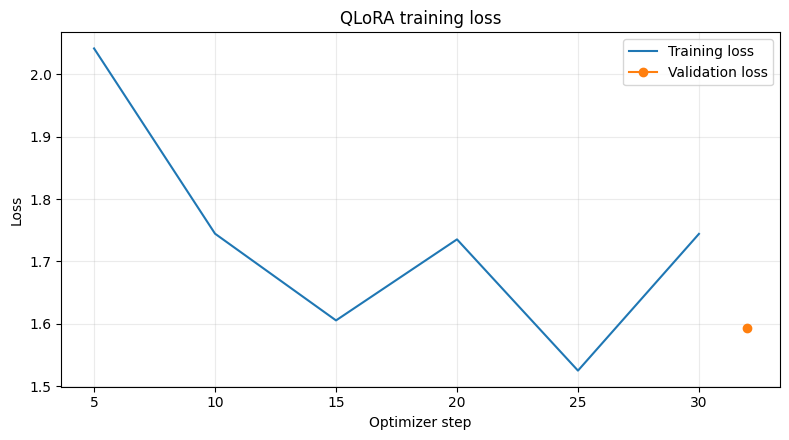

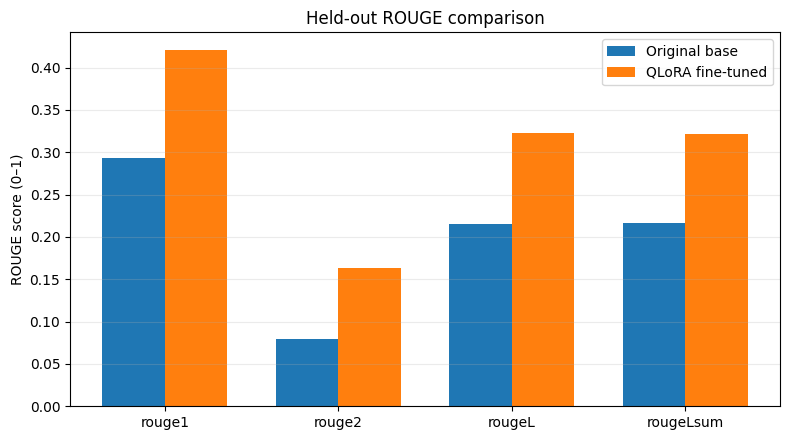

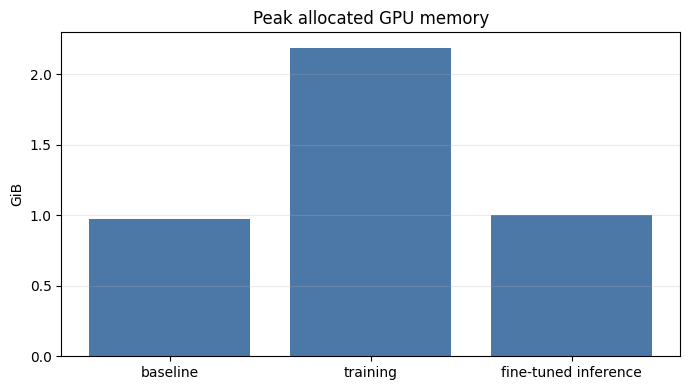

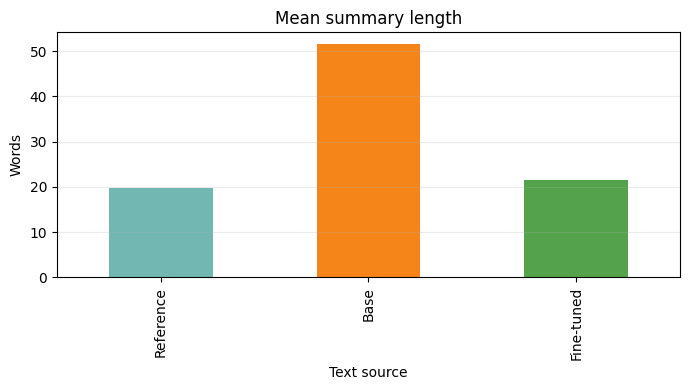

In [17]:
import matplotlib.pyplot as plt
# Training and validation losses
fig, ax = plt.subplots(figsize=(8,4.5))
if "loss" in history and "step" in history:
    tr = history.dropna(subset=["loss"]); ax.plot(tr.step, tr.loss, label="Training loss")
if "eval_loss" in history and "step" in history:
    ev = history.dropna(subset=["eval_loss"]); ax.plot(ev.step, ev.eval_loss, marker="o", label="Validation loss")
ax.set(title="QLoRA training loss", xlabel="Optimizer step", ylabel="Loss"); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS_DIR/"training_loss.png", dpi=180); plt.show()

# Base versus tuned ROUGE
metric_cols = [c for c in ("rouge1","rouge2","rougeL","rougeLsum") if c in comparison.columns]
fig, ax = plt.subplots(figsize=(8,4.5)); x=np.arange(len(metric_cols)); width=.36
ax.bar(x-width/2, comparison.loc[0,metric_cols], width, label="Original base")
ax.bar(x+width/2, comparison.loc[1,metric_cols], width, label="QLoRA fine-tuned")
ax.set_xticks(x, metric_cols); ax.set_ylim(bottom=0); ax.set(title="Held-out ROUGE comparison", ylabel="ROUGE score (0–1)")
ax.grid(axis="y",alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(RESULTS_DIR/"rouge_comparison.png",dpi=180); plt.show()

# VRAM peak and summary lengths for both generations
mem = {"baseline":base_memory, "training":training_memory, "fine-tuned inference":finetuned_memory}
peak = {k:v.get("peak_allocated_gib") for k,v in mem.items() if v}
if peak:
    fig,ax=plt.subplots(figsize=(7,4)); ax.bar(list(peak),list(peak.values()),color="#4C78A8")
    ax.set(title="Peak allocated GPU memory",ylabel="GiB"); ax.grid(axis="y",alpha=.25); fig.tight_layout()
    fig.savefig(RESULTS_DIR/"gpu_memory.png",dpi=180); plt.show()
lengths=pd.DataFrame({"Reference": [len(s.split()) for s in references],
                      "Base": [len(s.split()) for s in base_predictions],
                      "Fine-tuned": [len(s.split()) for s in finetuned_predictions]})
fig,ax=plt.subplots(figsize=(7,4)); lengths.mean().plot(kind="bar",ax=ax,color=["#72B7B2","#F58518","#54A24B"])
ax.set(title="Mean summary length",ylabel="Words",xlabel="Text source"); ax.grid(axis="y",alpha=.25); fig.tight_layout()
fig.savefig(RESULTS_DIR/"summary_lengths.png",dpi=180); plt.show()


### Qualitative comparison

Review real examples in a table. A higher aggregate metric can hide omissions or invented details, so use these side-by-side outputs for error analysis.


In [18]:
example_count = min(5, len(eval_dialogues))
display(pd.DataFrame({"Dialogue":eval_dialogues[:example_count],
                      "Reference":references[:example_count],
                      "Base model":base_predictions[:example_count],
                      "Fine-tuned model":finetuned_predictions[:example_count]}))


,Dialogue,Reference,Base model,Fine-tuned model
0,Claire: <file_photo>\nKim: Looks delicious...\...,Both Claire and Linda are making curry for din...,The conversation is between Claire and Kim abo...,Claire is preparing a curry with Kim's file ph...
1,Alyssa: Have you seen Fergie’s national anthem...,Derek and Alyssa make fun of Fergie's performa...,Alyssa and Derek discuss Fergie's national ant...,Fergie's national anthem was performed by Illu...
2,"Ann: Hi, is the laptop still available?\nJosh:...",Ann wants to buy Josh's laptop for $200. Josh ...,"In this conversation, Ann asks Josh if the lap...",Josh has a laptop that Ann can buy with 200 do...
3,Matt: have you heard that Bon Jovi are coming ...,Matt and Tony want to go to the concert of Bon...,"In this conversation, Matt informs his friends...",Matt is going to Poland with Tony. He wants to...
4,Anastasia: Our new school photos\nAnastasia: <...,Anastasia sent her new school photos to Darrell.,**Summary:**\n\nAnastasia is sharing her schoo...,Anastasia is sad because she doesn't feel happ...


## 16. Saved Deliverables

The `results/` folder contains the baseline and fine-tuned ROUGE JSON files, the exact evaluation IDs, the evaluation manifest, paired predictions, training logs, runtime/GPU memory measurements, and plots. The `artifacts/qlora_adapter/` folder contains the PEFT adapter and tokenizer files. The base model weights are not copied into the adapter folder.
